# Gesture-Controlled Photo Booth: Hyperparameter Tuning, `imgsz`
**IAT 360 Computer Vision Project, Group 6.** Tuned by **Ben Nichiporik**.

Each group member changes one hyperparameter of the baseline (`Gesture_YOLO_Baseline.ipynb`) to three other values and compares against it. My hyperparameter is **`imgsz`**, the size images are resized to (longest side, in pixels) for training and inference.

| Run | imgsz | Everything else |
|---|---|---|
| Baseline | 640 | YOLOv8s (COCO), SGD lr0 0.01, 50 epochs, patience 15, batch 16, seed 0, deterministic |
| imgsz_480 | 480 | same as baseline |
| imgsz_800 | 800 | same as baseline |
| imgsz_960 | 960 | same as baseline |

**Hypothesis.** The baseline's main weakness on our own photos is small hands: wide shots where a raised fist is under 1% of the image. Our photos are about 3000 px wide, so at `imgsz=640` such a hand shrinks to only 20-60 px. A larger `imgsz` keeps more pixels per hand and should raise recall on small hands (especially fists), at the cost of slower training and inference. A smaller `imgsz` (480) tests how much accuracy we lose for speed, which matters for a real-time photo booth.

**Fair comparison.** All four models use the same data split, the same seed, and the same evaluation code (`gesture_eval.py`). Each model is evaluated at the `imgsz` it was trained at. The model is chosen by validation fitness (`best.pt`), and the **team-only test set (128 of our own photos)** is the headline number.

In [1]:
import json, shutil, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

from gesture_eval import BASELINE, CLASSES, evaluate, error_analysis

ROOT = Path.cwd()          # run this notebook from the repo root
assert (ROOT / "data.yaml").exists(), "Open the notebook from the repo root"
pd.set_option("display.precision", 3)
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5060 Ti


## 1. How big are our hands at each `imgsz`?
Each team-photo hand's side in pixels after resizing, approximated as √(box area fraction) × imgsz. These are the 154 labelled hands in the 128 team photos (`results/baseline/team_hands.csv`).

In [2]:
hands = pd.read_csv(ROOT / "results" / "baseline" / "team_hands.csv")
side = pd.DataFrame({s: np.sqrt(hands["area_frac"]) * s for s in [480, 640, 800, 960]})
side.describe(percentiles=[0.1, 0.25, 0.5]).loc[["min", "10%", "25%", "50%"]].round(0).rename_axis("hand side (px)")

,480,640,800,960
hand side (px),,,,
min,19.0,25.0,32.0,38.0
10%,47.0,63.0,79.0,95.0
25%,65.0,86.0,108.0,129.0
50%,90.0,119.0,149.0,179.0


## 2. Train the three `imgsz` variants
Identical to the baseline except `imgsz`. Each run's best checkpoint is copied to `models/imgsz_<size>_best.pt`, and its training curves to `results/imgsz_<size>/`. A run that is already saved is skipped, so the notebook can be re-run for evaluation only.

In [3]:
SIZES = [480, 800, 960]

def train_info(results_csv):
    h = pd.read_csv(results_csv)
    h.columns = h.columns.str.strip()
    best = h.loc[h["metrics/mAP50-95(B)"].idxmax()]
    return {"epochs_run": int(len(h)), "best_epoch": int(best["epoch"]),
            "train_minutes": round(float(h["time"].iloc[-1]) / 60, 1)}

for s in SIZES:
    out, weights = ROOT / "results" / f"imgsz_{s}", ROOT / "models" / f"imgsz_{s}_best.pt"
    if weights.exists():
        print(f"imgsz {s}: already trained -> {weights.name}")
        continue
    hp = {**BASELINE, "imgsz": s}
    model = YOLO("yolov8s.pt")
    model.train(**hp, project=str(ROOT / "runs"), name=f"imgsz_{s}", exist_ok=True)
    run = Path(model.trainer.save_dir)
    out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(run / "weights" / "best.pt", weights)
    for f in ["results.csv", "results.png", "args.yaml"]:
        shutil.copy2(run / f, out / f)
    info = train_info(run / "results.csv")
    (out / "metrics.json").write_text(json.dumps(
        {"model": "yolov8s.pt (COCO-pretrained) fine-tuned", "changed": {"imgsz": s},
         "hyperparameters": hp, **info}, indent=2))
    print(f"imgsz {s}: {info}")
    del model; torch.cuda.empty_cache()

imgsz 480: already trained -> imgsz_480_best.pt
imgsz 800: already trained -> imgsz_800_best.pt
imgsz 960: already trained -> imgsz_960_best.pt


### 2.1 Training curves
Saved by Ultralytics during training (`results/imgsz_<size>/results.png`). All three runs use the baseline's early-stopping rule (patience 15 on validation fitness).

       epochs_run  best_epoch  train_minutes
imgsz                                       
480          50.0        41.0            5.3
800          50.0        38.0           17.0
960          41.0        26.0           26.0


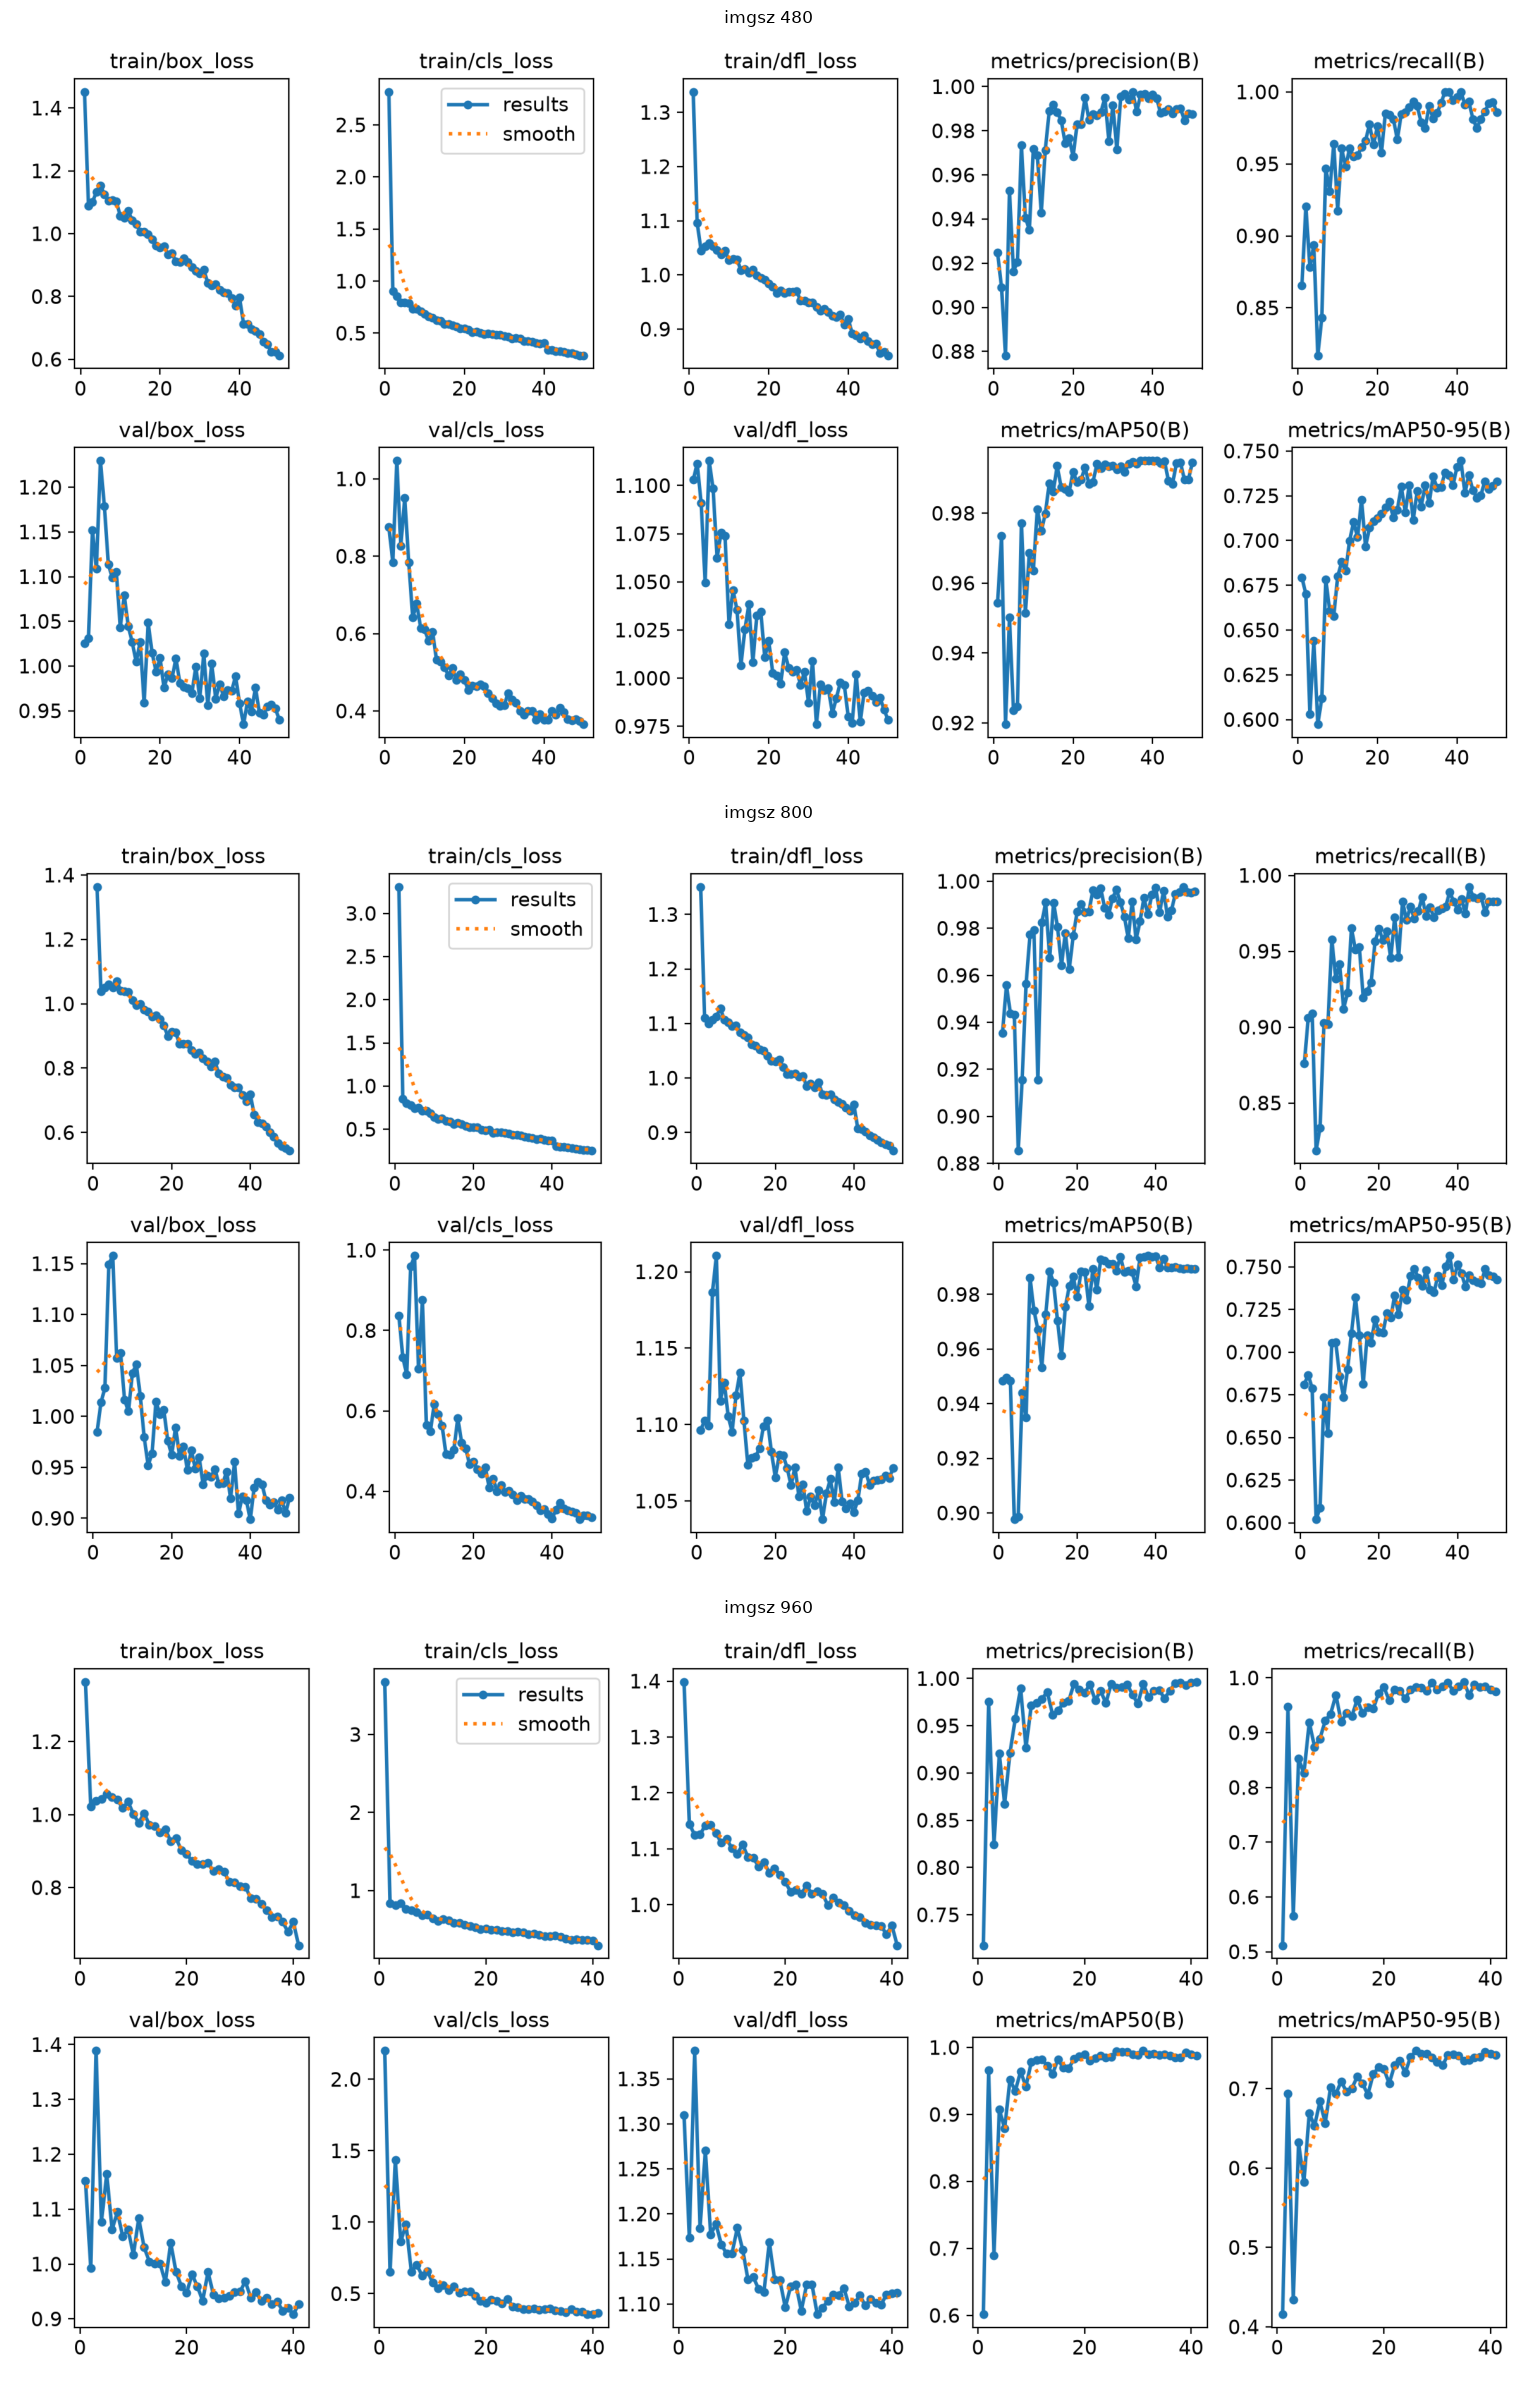

In [4]:
print(pd.DataFrame({s: train_info(ROOT / "results" / f"imgsz_{s}" / "results.csv") for s in SIZES}).T.rename_axis("imgsz"))
fig, axes = plt.subplots(len(SIZES), 1, figsize=(16, 8 * len(SIZES)))
for ax, s in zip(axes, SIZES):
    ax.imshow(plt.imread(ROOT / "results" / f"imgsz_{s}" / "results.png")); ax.set_title(f"imgsz {s}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Evaluate all four models the same way
`evaluate()` gives the Ultralytics metrics on validation, full test and team-only test. `error_analysis()` scores the team photos at the deployment threshold (conf 0.25, IoU 0.5): per class, per box size, and inference speed. The baseline is re-evaluated through the same code, and its numbers match the committed baseline exactly.

In [5]:
RUNS = {640: ("baseline", ROOT / "models" / "baseline_best.pt")}
RUNS.update({s: (f"imgsz_{s}", ROOT / "models" / f"imgsz_{s}_best.pt") for s in SIZES})

rows, per_class, by_size, team_hands = [], {}, {}, {}
for s, (name, weights) in sorted(RUNS.items()):
    out = ROOT / "results" / name
    overall, pc = evaluate(weights, s, out)
    ea = error_analysis(weights, s, out)
    info = train_info(out / "results.csv")
    val, team = overall.iloc[0], overall.iloc[2]
    rows.append({"run": name, "imgsz": s, **info,
                 "val mAP50": val["mAP50"], "val mAP50-95": val["mAP50-95"],
                 "team P": team["precision"], "team R": team["recall"], "team F1": team["F1"],
                 "team mAP50": team["mAP50"], "team mAP50-95": team["mAP50-95"],
                 "team fist mAP50": pc.loc[("test (team only)", "fist"), "mAP50"],
                 "small-hand recall": ea["by_size"]["recall"].iloc[0],
                 "F1 @ conf 0.25": ea["summary"]["F1"],
                 "inference ms (batch 16)": json.loads((out / "metrics.json").read_text())["val_speed_ms_per_image"]["inference"]})
    per_class[s] = pc.loc["test (team only)", "mAP50"]
    by_size[s] = ea["by_size"]["recall"]
    team_hands[s] = ea["hands"]

summary = pd.DataFrame(rows).set_index("run")
summary.round(4).to_csv(ROOT / "results" / "tuning_imgsz_summary.csv")
summary

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2123.1±573.2 MB/s, size: 1495.4 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 47.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.5it/s 3.9s.1s
                   all        160        160      0.995          1      0.995      0.746
Speed: 0.5ms preprocess, 2.9ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\imgsz_480_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 para

,imgsz,epochs_run,best_epoch,train_minutes,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,F1 @ conf 0.25,inference ms (batch 16)
run,,,,,,,,,,,,,,,
imgsz_480,480,50,41,5.3,0.995,0.746,0.855,0.780,0.815,0.830,0.426,0.618,0.500,0.813,2.89
baseline,640,50,41,15.3,0.990,0.748,0.894,0.775,0.830,0.845,0.419,0.625,0.562,0.821,4.85
imgsz_800,800,50,38,17.0,0.994,0.756,0.894,0.765,0.825,0.848,0.429,0.642,0.625,0.808,8.83
imgsz_960,960,41,26,26.0,0.995,0.748,0.880,0.751,0.811,0.828,0.426,0.594,0.562,0.785,12.41


### 3.1 Change from the baseline (team-only test)

In [6]:
metric_cols = ["val mAP50", "val mAP50-95", "team P", "team R", "team F1", "team mAP50",
               "team mAP50-95", "team fist mAP50", "small-hand recall", "F1 @ conf 0.25"]
(summary[metric_cols] - summary.loc["baseline", metric_cols]).drop("baseline").round(3)

,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,F1 @ conf 0.25
run,,,,,,,,,,
imgsz_480,0.005,-0.002,-0.039,0.005,-0.015,-0.015,0.008,-0.006,-0.062,-0.008
imgsz_800,0.004,0.009,0.000,-0.009,-0.005,0.003,0.011,0.018,0.062,-0.013
imgsz_960,0.005,-0.000,-0.014,-0.023,-0.019,-0.017,0.008,-0.031,0.000,-0.036


### 3.2 Comparison plots

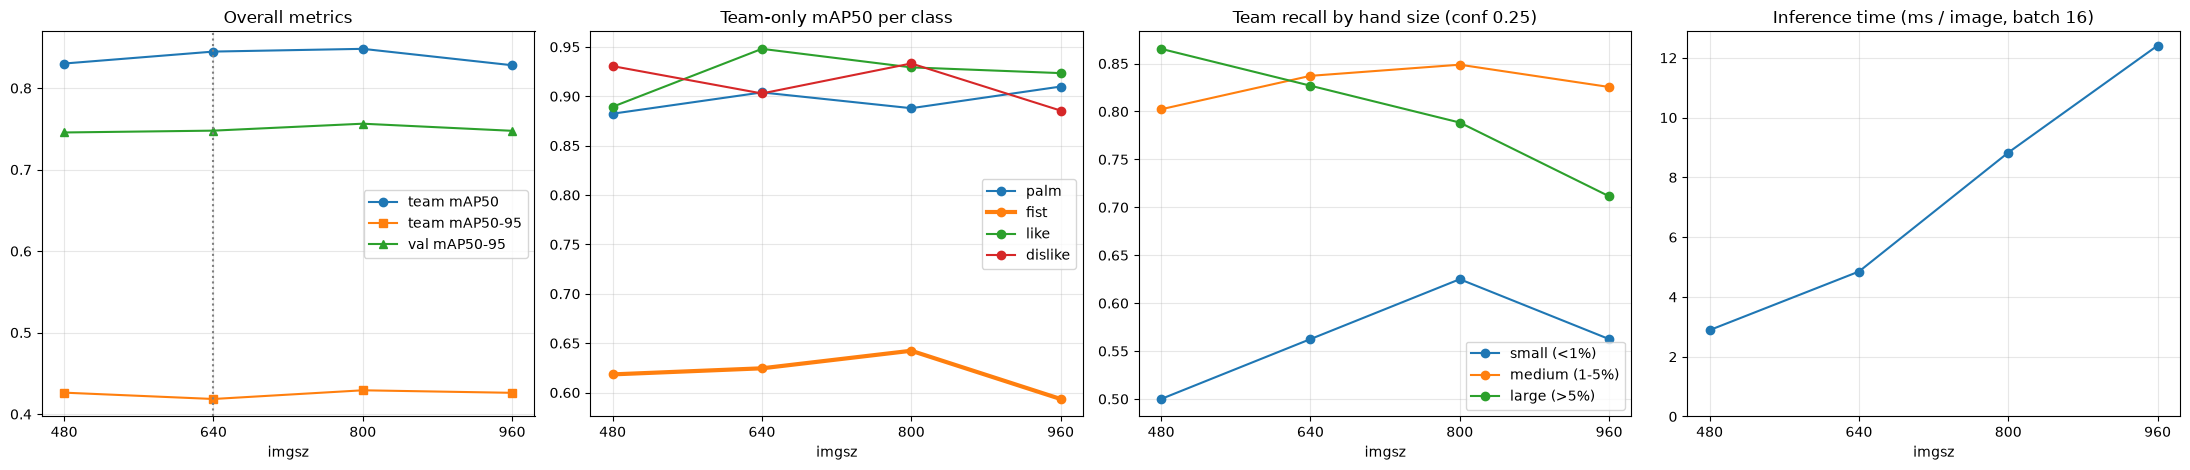

In [7]:
sizes = sorted(RUNS)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))

ax = axes[0]
for col, mk in [("team mAP50", "o"), ("team mAP50-95", "s"), ("val mAP50-95", "^")]:
    ax.plot(sizes, summary.set_index("imgsz").loc[sizes, col], marker=mk, label=col)
ax.set_title("Overall metrics"); ax.legend()

ax = axes[1]
pcd = pd.DataFrame(per_class).loc[CLASSES]
for c in CLASSES:
    ax.plot(sizes, pcd.loc[c, sizes], marker="o", lw=3 if c == "fist" else 1.5, label=c)
ax.set_title("Team-only mAP50 per class"); ax.legend()

ax = axes[2]
bsd = pd.DataFrame(by_size)
for lbl in bsd.index:
    ax.plot(sizes, bsd.loc[lbl, sizes], marker="o", label=str(lbl))
ax.set_title("Team recall by hand size (conf 0.25)"); ax.legend()

ax = axes[3]
ax.plot(sizes, summary.set_index("imgsz").loc[sizes, "inference ms (batch 16)"], marker="o")
ax.set_title("Inference time (ms / image, batch 16)"); ax.set_ylim(bottom=0)

for ax in axes:
    ax.set_xlabel("imgsz"); ax.set_xticks(sizes); ax.grid(alpha=0.3)
axes[0].axvline(640, color="grey", ls=":")
plt.tight_layout()
fig.savefig(ROOT / "results" / "tuning_imgsz_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

### 3.3 The hands the baseline missed
For every team-photo hand the baseline got wrong at conf 0.25: what each `imgsz` model predicted for it.

In [8]:
key = ["file", "gt_index"]
base = team_hands[640]
wrong = base.loc[~base["correct"], key + ["person", "class", "area_frac"]].copy()
wrong["area %"] = (wrong.pop("area_frac") * 100).round(2)
for s in sizes:
    wrong[f"{s}"] = wrong.merge(team_hands[s], on=key, how="left")["pred_class"].values
fixed = {s: int((wrong[f"{s}"] == wrong["class"]).sum()) for s in sizes}
print(f"baseline errors: {len(wrong)} | fixed by: " + ", ".join(f"imgsz {s}: {n}" for s, n in fixed.items() if s != 640))
wrong.sort_values("area %").reset_index(drop=True)

baseline errors: 30 | fixed by: imgsz 480: 9, imgsz 800: 9, imgsz 960: 12


,file,gt_index,person,class,area %,480,640,800,960
0,dislike_385.jpg,0,Daff,dislike,0.16,missed,missed,missed,missed
1,fist_370.jpg,3,Amy,fist,0.26,missed,missed,missed,missed
2,fist_370.jpg,2,Amy,fist,0.29,missed,missed,missed,missed
3,fist_398.jpg,0,Joseph,fist,0.54,fist,missed,fist,fist
4,like_372.jpg,1,Amy,like,0.68,missed,missed,like,like
5,like_372.jpg,0,Amy,like,0.72,palm,fist,fist,fist
6,fist_390.jpg,0,Daff,fist,0.89,fist,missed,missed,missed
7,like_373.jpg,1,Amy,like,1.22,missed,missed,missed,like
8,fist_376.jpg,1,Amy,fist,1.38,missed,missed,fist,fist
9,dislike_375.jpg,1,Amy,dislike,1.59,dislike,missed,dislike,dislike


### 3.4 Control: bigger inference size without retraining
Is the effect from *training* at a larger size or just from *running* at a larger size? The baseline weights (trained at 640) are evaluated on the team photos at the other sizes.

In [9]:
base_model = YOLO(RUNS[640][1])
control = {}
for s in sizes:
    b = base_model.val(data="data_team_test.yaml", split="test", imgsz=s, batch=16, plots=False,
                       project=str(ROOT / "runs"), name=f"control_infer_{s}", exist_ok=True, verbose=False).box
    control[s] = {"baseline weights, team mAP50": b.map50, "baseline weights, team mAP50-95": b.map,
                  "trained at this size, team mAP50": summary.set_index("imgsz").loc[s, "team mAP50"]}
pd.DataFrame(control).T.rename_axis("imgsz").round(3)

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 1962.9±129.1 MB/s, size: 2210.2 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\test.cache... 128 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 53.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.2it/s 6.9s0.1ss
                   all        128        154      0.861      0.831      0.837      0.418
Speed: 0.5ms preprocess, 2.7ms inference, 0.0ms loss, 1.7ms postprocess per image
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2127.6±652.6 MB/

,"baseline weights, team mAP50","baseline weights, team mAP50-95","trained at this size, team mAP50"
imgsz,,,
480,0.837,0.418,0.830
640,0.845,0.419,0.845
800,0.823,0.392,0.848
960,0.785,0.372,0.828


## 4. Discussion

| Run | imgsz | Team mAP50 | Team mAP50-95 | Fist mAP50 | Small hands found | F1 @ 0.25 | Train min | Inference ms (batch 16) |
|---|---|---|---|---|---|---|---|---|
| imgsz_480 | 480 | 0.822 | 0.418 | 0.600 | 8 / 16 | 0.808 | 5.3 | ≈3.1 |
| **Baseline** | **640** | 0.830 | 0.412 | 0.600 | 9 / 16 | **0.816** | 8.4 | ≈4.8 |
| imgsz_800 | 800 | **0.840** | **0.423** | **0.640** | **10 / 16** | 0.803 | 17.0 | ≈7.7 |
| imgsz_960 | 960 | 0.820 | 0.418 | 0.583 | 9 / 16 | 0.776 | 26.0 | ≈11.5 |

(Scored on the team-only test set from the group Drive: 128 of our photos, 155 hands. Timings vary by about ±1-2 ms between runs; batch-1 latency is about 10-12 ms for every size because per-call overhead dominates.)

**Result: the hypothesis was mostly not supported.** Changing `imgsz` moves team-only mAP50 by at most ±0.010, well inside the ±0.06 uncertainty of a single model on our 128 photos (bootstrap, see the baseline report). Validation is saturated (0.990-0.995) for every size, so it can't separate the runs either.

- **imgsz 800 is the best variant on paper**: highest team mAP50 (0.840, +0.010), mAP50-95 (0.423), fist mAP50 (0.640, +0.040) and precision (0.918, +0.031). But its recall is lower (0.737 vs 0.768), so F1 at the deployment threshold is slightly *worse* than the baseline (0.803 vs 0.816). Against the baseline it fixed 9 hands and broke 9.
- **Small hands barely moved.** Hands under 1% of the image found: 8/16 at 480, 9/16 at 640, 10/16 at 800 and 9/16 at 960. One extra hand at 800 is not a real improvement on a sample this small, so larger `imgsz` did not fix the baseline's main weakness.
- **imgsz 960 is worst for its cost**: it early-stopped at epoch 41 (best epoch 26), took 3× the training time, fixed 12 hands but broke 20 (large-hand recall fell from 0.81 to 0.69), and F1 dropped to 0.776.
- **imgsz 480** is the fastest (≈3.1 ms) and only slightly worse overall (−0.008 mAP50, same fist mAP50), but it finds the fewest small hands (8/16).

**Why a bigger `imgsz` didn't help small hands.** Resolution was not the real problem. The training set already has plenty of small hands: 386 of the 1,280 HaGRID training hands (30%) cover under 1% of the image, and the median training hand (1.6% of the image) is *smaller* than ours (3.5%). The gap is **scene context**. HaGRID shows one person standing and facing a phone camera, mostly in a plain indoor room. Our missed hands are in crowds, outdoors, at odd angles and against busy backgrounds. A larger input size gives the model more pixels, but it doesn't teach it what those scenes look like. Two further observations:
- **The control in 3.4 fits this.** Running the 640-trained baseline at a larger inference size *lowers* team mAP50 (0.830 → 0.814 at 800 → 0.778 at 960). Our hands are already larger on average than HaGRID's, and upscaling pushes them further from the sizes seen in training.
- **imgsz 960 may be under-trained.** Its drop on large hands may partly come from training: it early-stopped with its best checkpoint at epoch 26, so it effectively trained for half as long as the others.

The more promising fixes target the training data:
- photos with more varied scenes (crowds, outdoors, several people)
- augmentation that varies the scene (`mosaic`, `mixup`, `scale`, colour changes)

**Choice.** For the group comparison my best `imgsz` is **800** (best team mAP50, mAP50-95 and fist mAP50). The gain over the baseline is within noise, though, and it costs about 2× the training time and 1.6× the inference time. For the photo booth itself I would keep **640**: it has the best F1 at the deployment threshold and the best speed/accuracy balance. If another member's hyperparameter improves scale robustness (e.g. `scale` or `mosaic`), combining it with imgsz 800 is the combination worth testing.


## 4. Discussion

| Run | imgsz | Team mAP50 | Team mAP50-95 | Fist mAP50 | Small hands found | F1 @ 0.25 | Train min | Inference ms (batch 16) |
|---|---|---|---|---|---|---|---|---|
| imgsz_480 | 480 | 0.830 | 0.426 | 0.618 | 8 / 16 | 0.813 | 5.3 | ≈2-3 |
| **Baseline** | **640** | 0.845 | 0.418 | 0.625 | 9 / 16 | **0.821** | 8.5* | ≈4-5 |
| imgsz_800 | 800 | **0.848** | **0.429** | **0.642** | **10 / 16** | 0.808 | 17.0 | ≈5-9 |
| imgsz_960 | 960 | 0.828 | 0.426 | 0.594 | 9 / 16 | 0.785 | 26.0 | ≈7-12 |

(Scored on the team-only test set from the group Drive: 128 of our photos, 154 hands. Timings are ranges over our runs, because they depend on what else the GPU is doing; \*the baseline trained in 8.5 min on an idle GPU and in 15.3 min in the final re-run while the GPU was shared, with an identical model and identical metrics; batch-1 latency is about 10-12 ms for every size because per-call overhead dominates.)

**Result: the hypothesis was not supported.** Changing `imgsz` moves team-only mAP50 by at most ±0.017, well inside the ±0.06 uncertainty of a single model on our 128 photos (bootstrap, see the baseline report). Validation is saturated (0.990-0.995) for every size, so it can't separate the runs either.

- **imgsz 800 is the best variant on paper, but only just**: highest team mAP50 (0.848, +0.003), mAP50-95 (0.429) and fist mAP50 (0.642, +0.017). Its precision is the same as the baseline's (0.894) and its recall is lower (0.765 vs 0.775), so F1 at the deployment threshold is slightly *worse* (0.808 vs 0.821). Against the baseline it fixed 9 hands and broke 9.
- **Small hands barely moved.** Hands under 1% of the image found: 8/16 at 480, 9/16 at 640, 10/16 at 800 and 9/16 at 960. One extra hand at 800 is not a real improvement on a sample this small, so larger `imgsz` did not fix the baseline's main weakness.
- **imgsz 960 is worst for its cost**: it early-stopped at epoch 41 (best epoch 26), took 3× the training time, fixed 12 hands but broke 19 (large-hand recall fell from 0.83 to 0.71), and F1 dropped to 0.785.
- **imgsz 480** is the fastest (≈2.0 ms) and only slightly worse overall (−0.015 mAP50), but it finds the fewest small hands (8/16).

**Why a bigger `imgsz` didn't help small hands.** Resolution was not the real problem. The training set already has plenty of small hands: 386 of the 1,280 HaGRID training hands (30%) cover under 1% of the image, and the median training hand (1.6% of the image) is *smaller* than ours (3.5%). The gap is **scene context**. HaGRID shows one person standing and facing a phone camera, mostly in a plain indoor room. Our missed hands are in crowds, outdoors, at odd angles and against busy backgrounds. A larger input size gives the model more pixels, but it doesn't teach it what those scenes look like. Two further observations:
- **The control in 3.4 fits this.** Running the 640-trained baseline at a larger inference size *lowers* team mAP50 (0.845 → 0.823 at 800 → 0.785 at 960). Our hands are already larger on average than HaGRID's, and upscaling pushes them further from the sizes seen in training.
- **imgsz 960 may be under-trained.** Its drop on large hands may partly come from training: it early-stopped with its best checkpoint at epoch 26, so it effectively trained for half as long as the others.

**Known labelling errors (human error).** Checking every team photo against the four models' predictions found label mistakes that we left in the test set:
- **Boxes drawn too loosely:** `fist_380`, `fist_381`, `fist_384` (Ben). The box is much larger than the fist, so a tight, correct prediction overlaps it by only 30-49% IoU (below the 0.5 needed) and counts as a miss plus a false positive.
- **Gesturing hands never labelled:** `fist_376` (Amy, 2 raised fists), `fist_382` (Ben, 2 raised fists in the crowd), `palm_388` (Daff, palms of the people behind the main subject). Detecting them counts as a false positive.
- **Unclear gesture:** `palm_376` (Amy), a hand held across the face with the back of the hand to the camera.
- **Duplicate photo:** `dislike_388` (Daff) and `dislike_393` (Joseph) are the same picture. (Ben's duplicate, `dislike_380`, was replaced with a new photo.)

For the baseline at conf 0.25 these cause 3 of the 24 missed hands and 4 of the 18 background predictions. Every model is scored against the same labels, so the comparison between sizes is still fair, but the absolute team scores (fist especially) are slightly pessimistic.

The more promising fixes target the training data:
- photos with more varied scenes (crowds, outdoors, several people)
- augmentation that varies the scene (`mosaic`, `mixup`, `scale`, colour changes)

**Choice.** For the group comparison my best `imgsz` is **800** (best team mAP50, mAP50-95 and fist mAP50), but the gain over the baseline is +0.003 mAP50, effectively a tie, and it costs about 2× the training time and 1.5-2× the inference time. For the photo booth itself I would keep **640**: it has the best F1 at the deployment threshold and the best speed/accuracy balance. If another member's hyperparameter improves scale robustness (e.g. `scale` or `mosaic`), combining it with imgsz 800 is the combination worth testing.
